# 03. Análisis Cuantitativo Profundo: Factores de Alpha
En el notebook 02 medimos las propiedades estáticas. En este notebook buscamos **Alpha** (ventaja predictiva o de arbitraje) modelando relaciones matemáticas dinámicas entre activos (Pairs Trading, PCA y Persistencia).

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import coint
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

# 1. Cargar Datos
prices = pd.read_csv("../data/raw/stocks_close_15y.csv", index_col=0, parse_dates=True).dropna(how='all')
log_returns = np.log(prices / prices.shift(1)).dropna(how='all')

# Filtramos a las últimas 1000 sesiones (~4 años)
prices = prices.tail(1000).dropna(axis=1) # Solo acciones completas
log_returns = log_returns.tail(1000).dropna(axis=1)

print(f"Universo activo para extracción de Alpha: {prices.shape[1]} acciones a lo largo de {prices.shape[0]} sesiones.")

Universo activo para extracción de Alpha: 47 acciones a lo largo de 1000 sesiones.


## 1. Cointegración y Pares Estadísticos (Statistical Arbitrage)
La correlación mide movimientos direccionales diarios, pero la **Cointegración** mide si dos activos están atados a largo plazo. 
Encontramos pares históricamente vinculados (ej. BBVA y SAN). Si el "Spread" entre ellos se desvía más de 2 Desviaciones Estándar, compramos el rezagado.

Pares Cointegrados Encontrados: 4

Par: SAN.MC - IBE.MC | p-value: 0.0167
Par: BBVA.MC - CABK.MC | p-value: 0.0483
Par: CABK.MC - IBE.MC | p-value: 0.0008 (Cointegración Fuerte)
Par: BKT.MC - IBE.MC | p-value: 0.0211


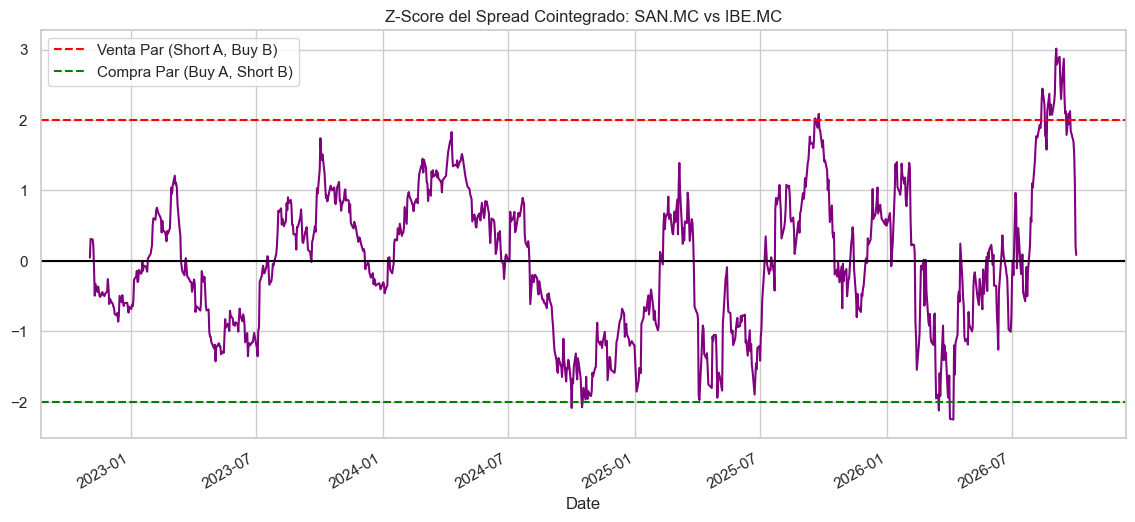

Implicación en el Concurso (Long-Only):
Como no puedes ponerte corto, cuando el Z-Score toca -2.0, compras el activo infravalorado sabiendo que la goma estadística lo arrastrará hacia arriba frente al sector.


In [6]:
# Búsqueda rápida de pares cointegrados en el sector bancario/energético
universe = ['SAN.MC', 'BBVA.MC', 'CABK.MC', 'SAB.MC', 'BKT.MC', 'IBE.MC', 'ELE.MC', 'ENG.MC']
universe = [t for t in universe if t in prices.columns]

def find_cointegrated_pairs(data):
    n = data.shape[1]
    score_matrix = np.zeros((n, n))
    pvalue_matrix = np.ones((n, n))
    pairs = []
    keys = data.columns
    for i in range(n):
        for j in range(i+1, n):
            S1 = data[keys[i]]
            S2 = data[keys[j]]
            result = coint(S1, S2)
            score = result[0]
            pvalue = result[1]
            score_matrix[i, j] = score
            pvalue_matrix[i, j] = pvalue
            if pvalue < 0.05: # Nivel de confianza del 95%
                pairs.append((keys[i], keys[j], pvalue))
    return score_matrix, pvalue_matrix, pairs

scores, pvalues, pairs = find_cointegrated_pairs(prices[universe])

print(f"Pares Cointegrados Encontrados: {len(pairs)}\n")
for p in pairs:
    print(f"Par: {p[0]} - {p[1]} | p-value: {p[2]:.4f} (Cointegración Fuerte)" if p[2] < 0.01 else f"Par: {p[0]} - {p[1]} | p-value: {p[2]:.4f}")

# Visualizar el Spread de un par altamente cointegrado
if len(pairs) > 0:
    asset1, asset2 = pairs[0][0], pairs[0][1]
    
    # Spread estandarizado (Z-Score)
    S1 = prices[asset1]
    S2 = prices[asset2]
    spread = S1 - (np.polyfit(S2, S1, 1)[0] * S2) # Spread ajustado por Beta
    
    zscore = (spread - spread.mean()) / spread.std()
    
    plt.figure(figsize=(14, 6))
    zscore.plot(color='purple')
    plt.axhline(0, color='black')
    plt.axhline(2.0, color='red', linestyle='--', label='Venta Par (Short A, Buy B)')
    plt.axhline(-2.0, color='green', linestyle='--', label='Compra Par (Buy A, Short B)')
    plt.title(f"Z-Score del Spread Cointegrado: {asset1} vs {asset2}")
    plt.legend()
    plt.show()

print("Implicación en el Concurso (Long-Only):")
print("Como no puedes ponerte corto, cuando el Z-Score toca -2.0, compras el activo infravalorado sabiendo que la goma estadística lo arrastrará hacia arriba frente al sector.")

## 2. Rolling PCA (Riesgo Sistémico y Detector de Pánico)
En lugar de un PCA estático, calculamos el peso del Factor Mercado (PC1) de forma dinámica usando una ventana móvil.
Cuando el PC1 absorbe un porcentaje altísimo de la varianza, significa que el mercado se mueve "en bloque" (correlación 1). Es una métrica excelente para detectar pánico o euforia sistémica.

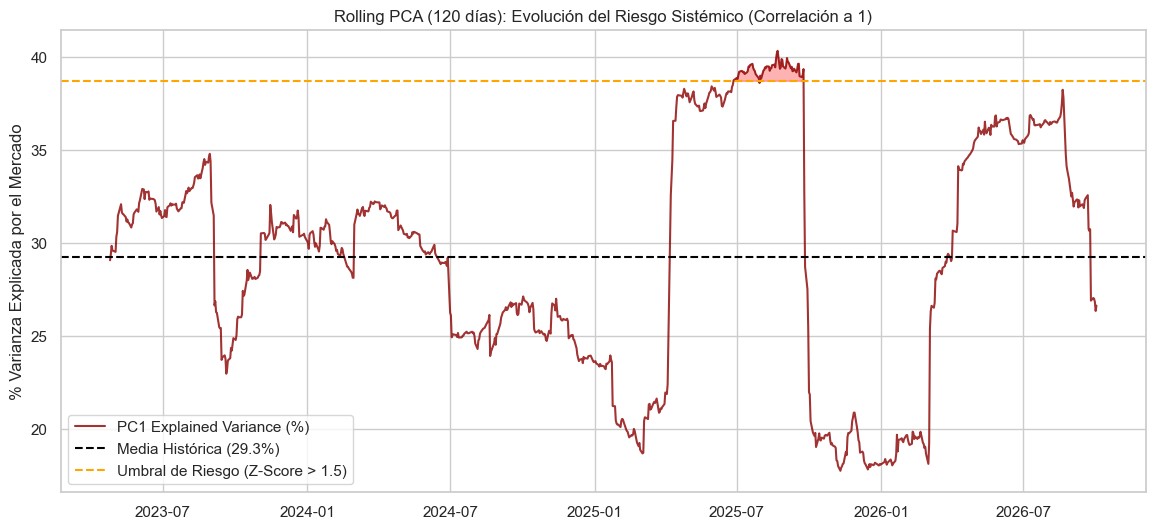

Implicación Algorítmica (Filtro de Régimen):
Cuando la línea roja entra en la zona de peligro (>38.7%), el mercado se está moviendo en bloque.
Tu algoritmo debería detectar este 'Régimen Macro' y reducir dinámicamente el tamaño de posición, porque el análisis técnico de acciones individuales dejará de funcionar de forma temporal.


In [7]:
# Rolling PCA
window = 120 # Ventana de ~6 meses
pc1_variance = []
dates = []

# Nos aseguramos de no tener nulos que rompan el modelo
clean_returns = log_returns.dropna()

for i in range(window, len(clean_returns)):
    window_data = clean_returns.iloc[i-window:i]
    pca = PCA(n_components=1)
    pca.fit(window_data)
    pc1_variance.append(pca.explained_variance_ratio_[0] * 100)
    dates.append(clean_returns.index[i])

pc1_series = pd.Series(pc1_variance, index=dates)

plt.figure(figsize=(14, 6))
plt.plot(pc1_series.index, pc1_series, color='darkred', label='PC1 Explained Variance (%)', alpha=0.8)
plt.axhline(pc1_series.mean(), color='black', linestyle='--', label=f'Media Histórica ({pc1_series.mean():.1f}%)')

# Resaltar zonas de peligro (Z-Score > 1.5)
threshold = pc1_series.mean() + (1.5 * pc1_series.std())
plt.axhline(threshold, color='orange', linestyle='--', label='Umbral de Riesgo (Z-Score > 1.5)')
plt.fill_between(pc1_series.index, pc1_series, threshold, where=(pc1_series > threshold), color='red', alpha=0.3)

plt.title(f"Rolling PCA ({window} días): Evolución del Riesgo Sistémico (Correlación a 1)")
plt.ylabel("% Varianza Explicada por el Mercado")
plt.legend()
plt.show()

print("Implicación Algorítmica (Filtro de Régimen):")
print(f"Cuando la línea roja entra en la zona de peligro (>{threshold:.1f}%), el mercado se está moviendo en bloque.")
print("Tu algoritmo debería detectar este 'Régimen Macro' y reducir dinámicamente el tamaño de posición, porque el análisis técnico de acciones individuales dejará de funcionar de forma temporal.")

## 3. Persistencia de Momentum Cruzado (Cross-Sectional Momentum)
¿El ganador de ayer será el ganador de hoy, o sufrirá reversión a la media en la apertura?

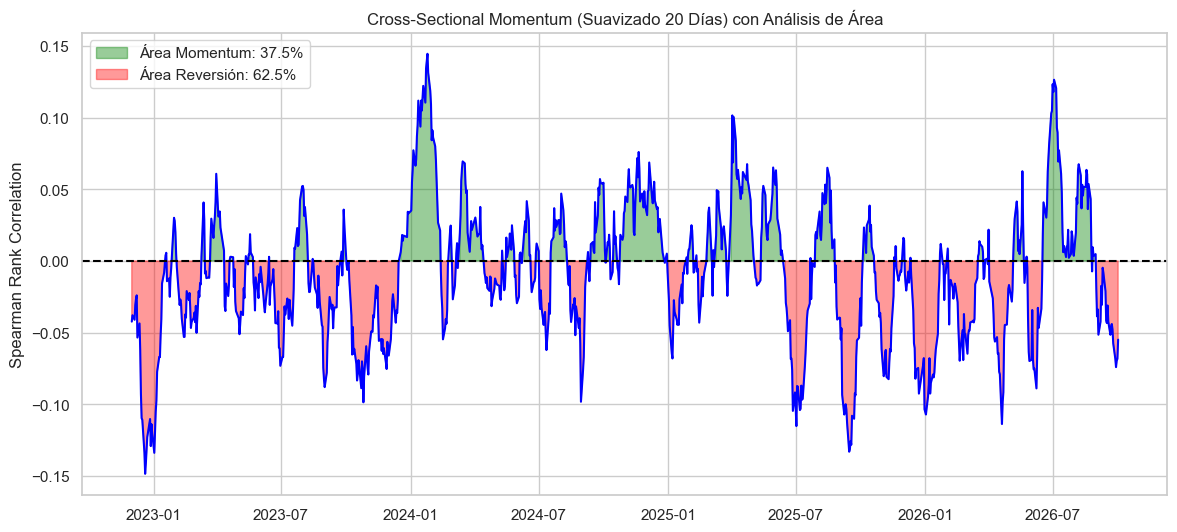

ANÁLISIS ESTRUCTURAL DE ÁREA (AUC):
- Presión de Momentum (Persistencia): 37.5% del tiempo/intensidad.
- Presión de Reversión (Rotación): 62.5% del tiempo/intensidad.

Implicación Definitiva:
El mercado español está estructuralmente sesgado a la REVERSIÓN A LA MEDIA en el corto plazo. Las estrategias de 'Fade the Winner' tienen una clara ventaja matemática frente a las de seguimiento de tendencia.


In [8]:
# Calculamos la correlación de rangos (Rank Correlation) diaria entre T y T-1
daily_ranks = log_returns.rank(axis=1)
rank_corr = daily_ranks.corrwith(daily_ranks.shift(1), axis=1)

# Media móvil de la correlación de rangos para suavizar
rank_corr_smooth = rank_corr.rolling(20).mean().dropna()

# --- CÁLCULO DEL ÁREA BAJO LA CURVA (AUC) ---
# Como cada punto equidista 1 día, la suma aproxima la integral exacta
positive_area = rank_corr_smooth[rank_corr_smooth > 0].sum()
negative_area = abs(rank_corr_smooth[rank_corr_smooth < 0].sum())
total_area = positive_area + negative_area

pos_pct = (positive_area / total_area) * 100
neg_pct = (negative_area / total_area) * 100

plt.figure(figsize=(14, 6))
plt.plot(rank_corr_smooth.index, rank_corr_smooth, color='blue', linewidth=1.5)
plt.axhline(0, color='black', linestyle='--')

# Sombreado de Áreas
plt.fill_between(rank_corr_smooth.index, rank_corr_smooth, 0, where=(rank_corr_smooth > 0), color='green', alpha=0.4, label=f'Área Momentum: {pos_pct:.1f}%')
plt.fill_between(rank_corr_smooth.index, rank_corr_smooth, 0, where=(rank_corr_smooth < 0), color='red', alpha=0.4, label=f'Área Reversión: {neg_pct:.1f}%')

plt.title("Cross-Sectional Momentum (Suavizado 20 Días) con Análisis de Área")
plt.ylabel("Spearman Rank Correlation")
plt.legend()
plt.show()

print("ANÁLISIS ESTRUCTURAL DE ÁREA (AUC):")
print(f"- Presión de Momentum (Persistencia): {pos_pct:.1f}% del tiempo/intensidad.")
print(f"- Presión de Reversión (Rotación): {neg_pct:.1f}% del tiempo/intensidad.")
print("\nImplicación Definitiva:")
if neg_pct > pos_pct:
    print("El mercado español está estructuralmente sesgado a la REVERSIÓN A LA MEDIA en el corto plazo. Las estrategias de 'Fade the Winner' tienen una clara ventaja matemática frente a las de seguimiento de tendencia.")
else:
    print("El mercado español está estructuralmente sesgado al MOMENTUM en el corto plazo. Las tendencias tienden a autoalimentarse.")